In [44]:
import pandas as pd
import numpy as np 

In [45]:
df=pd.read_csv("../data/raw/fake_job_postings.csv")

In [46]:
df.shape

(17880, 18)

In [47]:
df.head()
df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')

In [48]:
model_df=df[["job_id","title","company_profile","description","requirements","benefits","fraudulent","industry","function"]].copy()
model_df.shape

(17880, 9)

In [49]:
model_df.isna().sum()

job_id                0
title                 0
company_profile    3308
description           1
requirements       2696
benefits           7212
fraudulent            0
industry           4903
function           6455
dtype: int64

In [50]:
model_df["fraudulent"].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

In [51]:
model_df["fraudulent"].value_counts(normalize=True)*100

fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64

In [52]:
text_cols=['title', 'company_profile', 'description', 'requirements', 'benefits']

In [53]:
model_df[text_cols]=model_df[text_cols].fillna("")

In [54]:
model_df.isna().sum()

job_id                0
title                 0
company_profile       0
description           0
requirements          0
benefits              0
fraudulent            0
industry           4903
function           6455
dtype: int64

In [55]:
model_df["combined_text"]=model_df[text_cols].agg(" ".join, axis=1)
model_df.head(2)

,job_id,title,company_profile,description,requirements,benefits,fraudulent,industry,function,combined_text
0,1,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,NaN,Marketing,"Marketing Intern We're Food52, and we've creat..."
1,2,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,Marketing and Advertising,Customer Service,Customer Service - Cloud Video Production 90 S...


In [56]:
model_df["description"]=model_df["description"].str.lower()
model_df["description"]=model_df["description"].str.replace(r"\s+"," ",regex=True)
model_df["description"]=model_df["description"].str.strip()

In [57]:
model_df["description_grps"] = "desc:" + model_df["description"]

In [58]:
empty=model_df["description"]== ""

In [59]:
model_df.loc[empty,"description_grps"]=("job:" + model_df.loc[empty,"job_id"].astype(str))

In [60]:
#Total posting
print(len(model_df))

# Unique groups
print(model_df["description_grps"].nunique())

#Empty desccription
empty.sum()

17880
14593


np.int64(2)

In [61]:
from sklearn.model_selection import StratifiedGroupKFold

In [62]:
x=model_df["combined_text"]
y=model_df["fraudulent"]
groups= model_df["description_grps"]

In [63]:
groups

0        desc:food52, a fast-growing, james beard award...
1        desc:organised - focused - vibrant - awesome!d...
2        desc:our client, located in houston, is active...
3        desc:the company: esri – environmental systems...
4        desc:job title: itemization review managerloca...
                               ...                        
17875    desc:just in case this is the first time you’v...
17876    desc:the payroll accountant will focus primari...
17877    desc:experienced project cost control staff en...
17878    desc:nemsia studios is looking for an experien...
17879    desc:who are we?vend is an award winning web b...
Name: description_grps, Length: 17880, dtype: str

Five fold creating

In [64]:
splitter=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
folds=list(splitter.split(x,y,groups=groups))

Here, 3 folds bcz 1 for training, 1 for validation and 1 for testing.

In [65]:
test=folds[0][1]
validation=folds[1][1]
train=np.concatenate([folds[2][1],folds[3][1],folds[4][1]])

In [66]:
train_df= model_df.iloc[train].copy()
train_df.head(3)

,job_id,title,company_profile,description,requirements,benefits,fraudulent,industry,function,combined_text,description_grps
4,5,Bill Review Manager,SpotSource Solutions LLC is a Global Human Cap...,job title: itemization review managerlocation:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,Hospital & Health Care,Health Care Provider,Bill Review Manager SpotSource Solutions LLC i...,desc:job title: itemization review managerloca...
8,9,HP BSM SME,Solutions3 is a woman-owned small business who...,implementation/configuration/testing/training ...,MUST BE A US CITIZEN.An active TS/SCI clearanc...,,0,Information Technology and Services,NaN,HP BSM SME Solutions3 is a woman-owned small b...,desc:implementation/configuration/testing/trai...
15,16,VP of Sales - Vault Dragon,Jungle Ventures is the leading Singapore based...,about vault dragon vault dragon is dropbox for...,Key Superpowers3-5 years of high-pressure sale...,"Basic: SGD 120,000Equity negotiable for a rock...",0,Facilities Services,Sales,VP of Sales - Vault Dragon Jungle Ventures is ...,desc:about vault dragon vault dragon is dropbo...


In [67]:
train_df.shape

(10728, 11)

In [68]:
validation_df=model_df.iloc[validation].copy()
validation_df.head(3)

,job_id,title,company_profile,description,requirements,benefits,fraudulent,industry,function,combined_text,description_grps
0,1,Marketing Intern,"We're Food52, and we've created a groundbreaki...","food52, a fast-growing, james beard award-winn...",Experience with content management systems a m...,,0,NaN,Marketing,"Marketing Intern We're Food52, and we've creat...","desc:food52, a fast-growing, james beard award..."
2,3,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"our client, located in houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,NaN,NaN,Commissioning Machinery Assistant (CMA) Valor ...,"desc:our client, located in houston, is active..."
3,4,Account Executive - Washington DC,Our passion for improving quality of life thro...,the company: esri – environmental systems rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,Computer Software,Sales,Account Executive - Washington DC Our passion ...,desc:the company: esri – environmental systems...


In [69]:
validation_df.shape

(3576, 11)

In [70]:
test_df=model_df.iloc[test].copy()
test_df.head()

,job_id,title,company_profile,description,requirements,benefits,fraudulent,industry,function,combined_text,description_grps
9,10,Customer Service Associate - Part Time,"Novitex Enterprise Solutions, formerly Pitney ...",the customer service associate will be based i...,Minimum Requirements:Minimum of 6 months custo...,,0,Financial Services,Customer Service,Customer Service Associate - Part Time Novite...,desc:the customer service associate will be ba...
10,11,ASP.net Developer Job opportunity at United St...,,position : #url_86fd830a95a64e2b30ceed829e63fd...,Position : #URL_86fd830a95a64e2b30ceed829e63fd...,Benefits - FullBonus Eligible - YesInterview T...,0,Information Technology and Services,Information Technology,ASP.net Developer Job opportunity at United St...,desc:position : #url_86fd830a95a64e2b30ceed829...
25,26,H1B SPONSOR FOR L1/L2/OPT,i28 Technologies has demonstrated expertise in...,"hello,wish you are doing good... this is regar...","JAVA, .NET, SQL, ORACLE, SAP, Informatica, Big...",,0,NaN,NaN,H1B SPONSOR FOR L1/L2/OPT i28 Technologies has...,"desc:hello,wish you are doing good... this is ..."
27,28,HAAD/DHA Licensed Doctors Opening in UAE,We the Medical Recruitment Team of Roland and ...,haad/dha licensed doctors opening in uaewe the...,RequirementsEndocrinologistGastroenterologistC...,Our client is one of the reputed and leading H...,0,Hospital & Health Care,Health Care Provider,HAAD/DHA Licensed Doctors Opening in UAE We th...,desc:haad/dha licensed doctors opening in uaew...
35,36,English Teacher Abroad,We help teachers get safe &amp; secure jobs ab...,"play with kids, get paid for it love travel? j...",University degree required. TEFL / TESOL / CEL...,See job description,0,Education Management,NaN,English Teacher Abroad We help teachers get s...,"desc:play with kids, get paid for it love trav..."


In [71]:
test_df.shape

(3576, 11)

In [72]:
for name,data in [("Train", train_df),("Validation",validation_df),("Test",test_df)]:
    print(name)
    print(data["fraudulent"].value_counts(normalize=True)*100)

Train
fraudulent
0    95.162192
1     4.837808
Name: proportion, dtype: float64
Validation
fraudulent
0    95.134228
1     4.865772
Name: proportion, dtype: float64
Test
fraudulent
0    95.162192
1     4.837808
Name: proportion, dtype: float64


I think we should verify that no description grp should appear in multiple partitions.

In [73]:
assert set(train_df["description_grps"]).isdisjoint(set(validation_df["description_grps"]))

In [74]:
assert set(train_df["description_grps"]).isdisjoint(set(test_df["description_grps"]))

In [75]:
assert set(validation_df["description_grps"]).isdisjoint(set(test_df["description_grps"]))

Finally!, let's train our first model

I'll use TF-IDF + Logistic Regression here, that means TF-IDF will convert job-posting text into numerical features and Logistic Regression will learn pattern with two target classes.

In [76]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression 
from sklearn.pipeline import Pipeline

In [77]:
model = Pipeline([("tfidf",TfidfVectorizer(ngram_range=(1,2),min_df=2)),
("classifier", LogisticRegression(class_weight="balanced",max_iter=1000))])

Let's train it!

In [78]:
model.fit(train_df["combined_text"],train_df["fraudulent"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


MODEL EVALUATION

In [80]:
from sklearn.metrics import (classification_report, confusion_matrix,average_precision_score, roc_auc_score)

So, we'll use predict() for predicted class 0 or 1 and predict_proba which will give estimated score for each class.

In [93]:
y_val=validation_df["fraudulent"]
y_val.value_counts()

fraudulent
0    3402
1     174
Name: count, dtype: int64

In [84]:
y_val.shape

(3576,)

In [91]:
val_pred = model.predict(validation_df["combined_text"])
val_pred[:30]

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
len(val_pred)

3576

In [92]:
pd.Series(val_pred).value_counts()

0    3404
1     172
Name: count, dtype: int64

Oh damn! See our actual dataset have 174 fraudulent posting ..and our model flagged 172 postings as fraudulent..that's awesome! But still we don't know yet whether these 172 are actually fraudulent.

Let's create our confusion matrix

In [95]:
cm=confusion_matrix(y_val, val_pred)
cm

array([[3365,   37],
       [  39,  135]])

So here 3365 is TN which means legitimate jobs which are correctly identified, 37 is FP that means they're legitimate jobs which flagged as fraud, and 39 is FN which means fraudulent jobs which are missed by model and 135 is TP it means they're fraudulent jobs which are correctly detected.

In [96]:
from sklearn.metrics import (precision_score,recall_score)

In [102]:
precision=precision_score(y_val,val_pred,pos_label=1)
precision

0.7848837209302325

In [101]:
recall= recall_score(y_val,val_pred,pos_label=1)
recall

0.7758620689655172

In [103]:
from sklearn.metrics import f1_score

In [106]:
f1=f1_score(y_val,val_pred,pos_label=1)
f1*100

78.03468208092485

In [110]:
val_scores = model.predict_proba(validation_df["combined_text"])[:,1]
val_scores[:10]

array([0.0897163 , 0.09036454, 0.06134307, 0.07872166, 0.03522839,
       0.0238563 , 0.02938584, 0.70556395, 0.03239971, 0.02846479])

In [111]:
from sklearn.metrics import average_precision_score

In [114]:
ap=average_precision_score(y_val,val_scores)
ap*100

85.51991719537256

In [115]:
from sklearn.metrics import precision_recall_curve

In [120]:
pr_precision,pr_recall,pr_thresholds= precision_recall_curve(y_val, val_scores)
print(len(pr_precision),
len(pr_recall),
len(pr_thresholds))

3159 3159 3158


In [122]:
import matplotlib.pyplot as plt

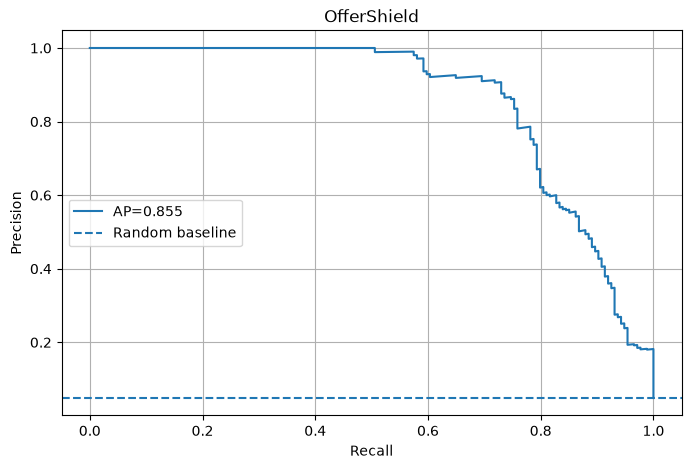

In [138]:
plt.figure(figsize=(8,5))
plt.plot(pr_recall,pr_precision,label=f"AP={ap:.3f}")
plt.axhline(y=y_val.mean(),linestyle="--",label="Random baseline")

plt.xlabel("Recall")
plt.ylabel("Precision") 
plt.title("OfferShield")
plt.legend()
plt.grid(True)
plt.show()

In [140]:
y_test=test_df["fraudulent"]
test_pred = model.predict(test_df["combined_text"])

In [143]:
test_score= model.predict_proba(test_df["combined_text"])[:,1]
test_score

array([0.02434986, 0.29867067, 0.07269319, ..., 0.41866156, 0.07862704,
       0.42526313], shape=(3576,))

In [146]:
a_p= average_precision_score(y_test,test_score)
a_p*100

88.74696790306686

In [149]:
from sklearn.metrics import (classification_report,confusion_matrix)

In [151]:
print(classification_report(y_test,test_pred,target_names=["Legitimate","Fraudulent"],digits=3))
print("Confusion Matrix:", confusion_matrix(y_test, test_pred))

              precision    recall  f1-score   support

  Legitimate      0.993     0.990     0.991      3403
  Fraudulent      0.818     0.855     0.836       173

    accuracy                          0.984      3576
   macro avg      0.905     0.923     0.914      3576
weighted avg      0.984     0.984     0.984      3576

Confusion Matrix: [[3370   33]
 [  25  148]]


Sector-level error analysis

In [157]:
test_df.head(1)

,job_id,title,company_profile,description,requirements,benefits,fraudulent,industry,function,combined_text,description_grps
9,10,Customer Service Associate - Part Time,"Novitex Enterprise Solutions, formerly Pitney ...",the customer service associate will be based i...,Minimum Requirements:Minimum of 6 months custo...,,0,Financial Services,Customer Service,Customer Service Associate - Part Time Novite...,desc:the customer service associate will be ba...


In [158]:
eval_df= test_df[["job_id","industry","function"]].copy()

In [168]:
eval_df["actual"]= y_test.to_numpy()
eval_df["predicted"]= test_pred
eval_df["fraud_score"]=test_score
eval_df.shape

(3576, 6)

In [169]:
eval_df.head()

,job_id,industry,function,actual,predicted,fraud_score
9,10,Financial Services,Customer Service,0,0,0.024350
10,11,Information Technology and Services,Information Technology,0,0,0.298671
25,26,NaN,NaN,0,0,0.072693
27,28,Hospital & Health Care,Health Care Provider,0,0,0.138595
35,36,Education Management,NaN,0,0,0.046195


In [185]:
fp_condition= ((eval_df["actual"]==0)& (eval_df["predicted"]==1))
fn_condition=((eval_df["actual"]==1)& (eval_df["predicted"]==0))

In [186]:
eval_df["error_type"]= np.select([fp_condition,fn_condition],["False Positive","False Negative"],default="Correct")
eval_df["error_type"].value_counts()

error_type
Correct           3518
False Positive      33
False Negative      25
Name: count, dtype: int64

How can error_type result is not matching my confusion matrix?


Oh! i did mistake , i put 0 instead of 1

In [184]:
print("TN:",((eval_df["actual"]==0)&(eval_df["predicted"]==0)).sum())

print("FP:",((eval_df["actual"]==0) & (eval_df["predicted"]==1)).sum())

print("FN:",((eval_df["actual"]==1) & (eval_df["predicted"]==0)).sum())

print("TP:",((eval_df["actual"]==1) & (eval_df["predicted"]==1)).sum())

TN: 3370
FP: 33
FN: 25
TP: 148


In [189]:
eval_df["industry_grp"]=eval_df["industry"].fillna("Unknown")
eval_df["industry_grp"].value_counts()

industry_grp
Unknown                                912
Education Management                   403
Information Technology and Services    311
Computer Software                      256
Internet                               191
                                      ... 
Investment Banking                       1
Photography                              1
Public Safety                            1
Plastics                                 1
Animation                                1
Name: count, Length: 108, dtype: int64

In [191]:
eval_df["legit"]=(eval_df["actual"]==0).astype(int)
eval_df["fraud"]=(eval_df["actual"]==1).astype(int)

In [193]:
eval_df["is_fp"]=((eval_df["actual"]==0)&(eval_df["predicted"]==1)).astype(int)

eval_df["is_fn"]=((eval_df["actual"]==1)&(eval_df["predicted"]==0)).astype(int)



In [200]:
report_industry= eval_df.groupby("industry_grp").agg(
    postings=("job_id","count"),
    legitimate=("legit","sum"),
    fraudulent=("fraud","sum"),
    false_positives=("is_fp","sum"),
    false_negatives=("is_fn","sum")
)

report_industry

,postings,legitimate,fraudulent,false_positives,false_negatives
industry_grp,,,,,
Accounting,32,18,14,1,1
Airlines/Aviation,15,15,0,1,0
Animation,1,0,1,0,0
Apparel & Fashion,26,26,0,0,0
Automotive,15,14,1,0,0
...,...,...,...,...,...
Unknown,912,854,58,17,6
Utilities,10,10,0,0,0
Venture Capital & Private Equity,7,7,0,0,0


In [203]:
report_industry["false_positive_rate"]=(report_industry["false_positives"]/report_industry["legitimate"]*100)

report_industry["false_negative_rate"]=(report_industry["false_negatives"]/report_industry["fraudulent"]*100)

report_industry.sort_values("postings",ascending=False).head()

,postings,legitimate,fraudulent,false_positives,false_negatives,false_positive_rate,false_negative_rate
industry_grp,,,,,,,
Unknown,912,854,58,17,6,1.990632,10.344828
Education Management,403,403,0,0,0,0.000000,NaN
Information Technology and Services,311,308,3,0,2,0.000000,66.666667
Computer Software,256,253,3,0,1,0.000000,33.333333
Internet,191,191,0,0,0,0.000000,NaN


In [204]:
eval_df["function_grp"] = eval_df["function"].fillna("Unknown")

In [205]:
report_function= eval_df.groupby("function_grp").agg(
    postings=("job_id", "count"),
    legitimate=("legit","sum"),
    fraudulent=("fraud","sum"),
    false_positives=("is_fp","sum"),
    false_negatives=("is_fn","sum")

)

In [207]:
report_function["false_positive_rate"]=(report_function["false_positives"]/ report_function["legitimate"]*100)
report_function["false_negative_rate"]=(report_function["false_negatives"]/ report_function["fraudulent"]*100)

In [208]:
report_function.sort_values("postings",ascending=False).head()

,postings,legitimate,fraudulent,false_positives,false_negatives,false_positive_rate,false_negative_rate
function_grp,,,,,,,
Unknown,1462,1414,48,17,12,1.202263,25.000000
Information Technology,345,338,7,0,2,0.000000,28.571429
Sales,262,255,7,0,0,0.000000,0.000000
Engineering,238,217,21,3,0,1.382488,0.000000
Customer Service,227,220,7,4,3,1.818182,42.857143


In [209]:
report_industry.to_csv("../data/processed/industry_error_report.csv")

In [210]:
report_function.to_csv("../data/processed/function_error_report.csv")

In [148]:
import joblib
import os

In [153]:
os.makedirs("../models",exist_ok=True)

In [154]:
joblib.dump(model,
"../models/offershield_pipeline.joblib")

['../models/offershield_pipeline.joblib']

In [155]:
os.path.exists("../models/offershield_pipeline.joblib")

True